BƯỚC 1: KIỂM TRA DỮ LIỆU TOÀN DIỆN
Encoding: {'movie.csv': 'utf-8', 'rating.csv': 'utf-8', 'tag.csv': 'utf-8', 'link.csv': 'utf-8', 'genome_tags.csv': 'utf-8', 'genome_scores.csv': 'utf-8'}

Đang quét rating.csv theo từng khối...
Đang quét genome_scores.csv theo từng khối...

=== BẢNG TỔNG HỢP KIỂM TRA 6 FILE ===


,File Name,Encoding,Total Rows,Expected Rows,Num Cols,Columns & Dtypes,Candidate Key,Key Duplicates,Exact Duplicate Rows,Orphan movieId,Orphan tagId,Rows Match README
0,movie.csv,utf-8,27278,27278,3,"movieId (int64), title (str), genres (str)",(movieId),0,0,0,0,True
1,link.csv,utf-8,27278,27278,3,"movieId (int64), imdbId (int64), tmdbId (float64)",(movieId),0,0,0,0,True
2,genome_tags.csv,utf-8,1128,1128,2,"tagId (int64), tag (str)",(tagId),0,0,0,0,True
3,tag.csv,utf-8,465564,465564,4,"userId (int64), movieId (int64), tag (str), ti...","(userId, movieId, tag)",0,0,0,0,True
4,rating.csv,utf-8,20000263,20000263,4,"userId (int64), movieId (int64), rating (float...","(userId, movieId)",0,0,0,0,True
5,genome_scores.csv,utf-8,11709768,11709768,3,"movieId (int64), tagId (int64), relevance (flo...","(movieId, tagId)",0,0,0,0,True


rating.csv   : rating trong [0.5, 5.0] | timestamp lỗi (NaT) = 0 | movieId không có trong movie.csv = 0
genome       : relevance trong [0.0003, 1.0000] | movieId không có trong movie.csv = 0
link.csv     : chỉ kiểm tra ở bước này, KHÔNG ghép vào df_clean (imdbId/tmdbId không phải đặc trưng).

BƯỚC 2: TẢI VÀ TÍCH HỢP DỮ LIỆU
1/3: Hợp nhất thống kê rating...
2/3: Tổng hợp tag.csv...
   Đã xóa 0 dòng tag trùng hoàn toàn.
3/3: Hợp nhất thống kê genome...

=> df_merged: (27278, 15)


,movieId,title,genres,rating_count,first_rated_dt,last_rated_dt,avg_rating,rating_std,tag_count,unique_tags,unique_taggers,tags_text,genome_score_count,max_relevance,mean_relevance
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,49695.0,1996-01-29 00:00:00+00:00,2015-03-30 19:57:57+00:00,3.921240,0.889012,436.0,80.0,152.0,watched | computer animation | disney animated...,1128.0,0.99925,0.160223
1,2,Jumanji (1995),Adventure|Children|Fantasy,22243.0,1996-01-29 00:00:00+00:00,2015-03-31 00:51:15+00:00,3.211977,0.951150,123.0,33.0,46.0,time travel | adapted from:book | board game |...,1128.0,0.98100,0.119486
2,3,Grumpier Old Men (1995),Comedy|Romance,12735.0,1996-02-01 14:33:48+00:00,2015-03-26 18:25:06+00:00,3.151040,1.006642,18.0,15.0,15.0,old people that is actually funny | sequel fev...,1128.0,0.97450,0.092403



BƯỚC 3: LÀM SẠCH DỮ LIỆU


,Missing Count,Missing (%)
rating_count,534,1.96
first_rated_dt,534,1.96
last_rated_dt,534,1.96
avg_rating,534,1.96
rating_std,4506,16.52
tag_count,7733,28.35
unique_tags,7733,28.35
unique_taggers,7733,28.35
tags_text,7733,28.35
genome_score_count,16897,61.94


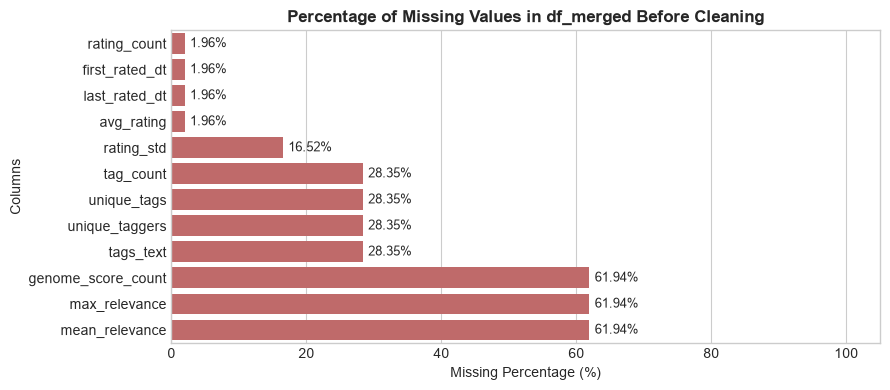

- Loại 534 phim không có rating (thiếu avg_rating).
- Ngưỡng rating_count >= 10: giữ 15451/26744 phim.
- 'mean_relevance': điền median tạm thời (trên phim có genome) = 0.111234
- 'max_relevance': điền median tạm thời (trên phim có genome) = 0.981500

KIỂM TRA df_clean TRƯỚC KHI BÀN GIAO
1. Số dòng (phim): 15,451 | movieId duy nhất: 15,451
2. Tổng NaN: 0
3. Số cột: 24


,count,mean,std,min,25%,50%,75%,max
avg_rating,15451.0,3.223657,0.502463,0.590909,2.925369,3.296512,3.598562,4.5


,movieId,title,genres,rating_count,first_rated_dt,last_rated_dt,avg_rating,rating_std,tag_count,unique_tags,...,mean_relevance,has_tag_data,has_genome,rating_span_days,release_year,year_missing,movie_age,decade,log_rating_count,log_tag_count
dtype,int64,str,str,int64,datetime64[us],datetime64[us],float64,float64,int64,int64,...,float64,int8,int8,int64,int64,int8,int64,int64,float64,float64



=> Đã xuất: C:\Users\hai27\Downloads\finalparten\df_clean.csv

LƯU Ý KHI ĐỌC LẠI FILE (Người 2 và Người 3):
  df = pd.read_csv('./data/df_clean.csv',
                   parse_dates=['first_rated_dt', 'last_rated_dt'],
                   keep_default_na=False, na_values=[])   # giữ tags_text rỗng là chuỗi rỗng


In [1]:
import os
import gc
import codecs
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor 

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

DATA_DIR = r'C:\Users\hai27\Downloads\finalparten'
FIG_DIR = r'C:\Users\hai27\Downloads\finalparten\figure'
os.makedirs(FIG_DIR, exist_ok=True)

FILES = ['movie.csv', 'rating.csv', 'tag.csv', 'link.csv', 'genome_tags.csv', 'genome_scores.csv']

EXPECTED_ROWS = {
    'rating.csv': 20_000_263, 'tag.csv': 465_564, 'movie.csv': 27_278,
    'link.csv': 27_278, 'genome_tags.csv': 1_128, 'genome_scores.csv': 11_709_768,
}

CHUNK_SIZE = 2_000_000            
REFERENCE_YEAR = 2015             
MIN_RATING_COUNT = 10             
APPLY_MIN_RATING_FILTER = True
ADD_DERIVED_FEATURES = True       


def raise_if(condition, message):
    """Dừng chương trình nếu dữ liệu nguồn vi phạm điều kiện chuẩn."""
    if condition:
        raise ValueError(message)


def detect_encoding(file_path, block_size=1024 * 1024):
    """Kiểm tra TOÀN BỘ file bằng incremental decoder (không lỗi khi ký tự bị cắt giữa 2 khối).
    Trả về tên encoding thật để truyền vào pd.read_csv(encoding=...)."""
    with open(file_path, 'rb') as f:
        has_bom = f.read(3) == codecs.BOM_UTF8
        f.seek(0)
        decoder = codecs.getincrementaldecoder('utf-8')()
        try:
            while chunk := f.read(block_size):
                decoder.decode(chunk, final=False)
            decoder.decode(b'', final=True)
        except UnicodeDecodeError:
            print(f'[CẢNH BÁO] {os.path.basename(file_path)} không phải UTF-8 -> đọc bằng latin1, '
                  f'tên phim/tag có thể sai chữ.')
            return 'latin1'
    return 'utf-8-sig' if has_bom else 'utf-8'


def parse_flexible_timestamp(ts_series):
    """Chuẩn hóa timestamp về datetime UTC. Hỗ trợ: số giây Unix (bản GroupLens gốc)
    hoặc chuỗi 'YYYY-MM-DD HH:MM:SS' (bản Kaggle). Giá trị lỗi -> NaT (không thành số âm)."""
    if pd.api.types.is_numeric_dtype(ts_series):
        return pd.to_datetime(ts_series, unit='s', errors='coerce', utc=True)
    return pd.to_datetime(ts_series, errors='coerce', utc=True)




print('=' * 75)
print('BƯỚC 1: KIỂM TRA DỮ LIỆU TOÀN DIỆN')
print('=' * 75)


ENCODINGS = {f: detect_encoding(os.path.join(DATA_DIR, f)) for f in FILES}
print('Encoding:', ENCODINGS)


def describe_cols(fname):
    sample = pd.read_csv(os.path.join(DATA_DIR, fname), nrows=1000, encoding=ENCODINGS[fname])
    return ', '.join(f'{c} ({d})' for c, d in sample.dtypes.items())



movies_raw      = pd.read_csv(os.path.join(DATA_DIR, 'movie.csv'),       encoding=ENCODINGS['movie.csv'])
links_raw       = pd.read_csv(os.path.join(DATA_DIR, 'link.csv'),        encoding=ENCODINGS['link.csv'])
genome_tags_raw = pd.read_csv(os.path.join(DATA_DIR, 'genome_tags.csv'), encoding=ENCODINGS['genome_tags.csv'])
tags_raw        = pd.read_csv(os.path.join(DATA_DIR, 'tag.csv'),         encoding=ENCODINGS['tag.csv'])

valid_movie_ids = set(movies_raw['movieId'].unique())
valid_tag_ids = set(genome_tags_raw['tagId'].unique())

inspection_records = []
small_tables = [
    ('movie.csv', movies_raw, ['movieId']),
    ('link.csv', links_raw, ['movieId']),
    ('genome_tags.csv', genome_tags_raw, ['tagId']),
    ('tag.csv', tags_raw, ['userId', 'movieId', 'tag']),  # tổ hợp dùng để kiểm tra trùng, chưa phải khóa chính đã xác nhận
]
for fname, df_obj, key_cols in small_tables:
    orphan_movies = int((~df_obj['movieId'].isin(valid_movie_ids)).sum()) if 'movieId' in df_obj.columns else 0
    inspection_records.append({
        'File Name': fname,
        'Encoding': ENCODINGS[fname],
        'Total Rows': len(df_obj),
        'Expected Rows': EXPECTED_ROWS[fname],
        'Num Cols': df_obj.shape[1],
        'Columns & Dtypes': describe_cols(fname),
        'Candidate Key': f"({', '.join(key_cols)})",
        'Key Duplicates': int(df_obj.duplicated(subset=key_cols).sum()),
        'Exact Duplicate Rows': int(df_obj.duplicated().sum()),
        'Orphan movieId': orphan_movies,
        'Orphan tagId': 0,
    })


raise_if(movies_raw['movieId'].duplicated().any(), 'movie.csv có movieId trùng.')
raise_if(genome_tags_raw['tagId'].duplicated().any(), 'genome_tags.csv có tagId trùng.')


print('\nĐang quét rating.csv theo từng khối...')
rating_fpath = os.path.join(DATA_DIR, 'rating.csv')
rs = dict(rows=0, orphan_movies=0, nan_rating=0, nat_ts=0, min=np.inf, max=-np.inf)
rating_pk_hashes, rating_chunk_aggs = [], []

for chunk in pd.read_csv(rating_fpath, chunksize=CHUNK_SIZE, encoding=ENCODINGS['rating.csv'],
                         dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32'}):
    chunk['ts_dt'] = parse_flexible_timestamp(chunk['timestamp'])  

    rs['rows'] += len(chunk)
    rs['orphan_movies'] += int((~chunk['movieId'].isin(valid_movie_ids)).sum())
    rs['nan_rating'] += int(chunk['rating'].isna().sum())
    rs['nat_ts'] += int(chunk['ts_dt'].isna().sum())
    rs['min'] = min(rs['min'], float(chunk['rating'].min()))
    rs['max'] = max(rs['max'], float(chunk['rating'].max()))

    
    raise_if((chunk['userId'] < 0).any() or (chunk['movieId'] < 0).any(), 'ID âm trong rating.csv.')
    h = (chunk['userId'].to_numpy(dtype='int64') << 32) | chunk['movieId'].to_numpy(dtype='int64')  
    rating_pk_hashes.append(h)

    r = chunk['rating'].astype('float64')
    c_agg = (chunk.assign(rating64=r, rating_sq=r ** 2)
             .groupby('movieId', as_index=False)
             .agg(c_count=('rating64', 'count'), c_sum=('rating64', 'sum'),
                  c_sum_sq=('rating_sq', 'sum'),
                  c_min_dt=('ts_dt', 'min'), c_max_dt=('ts_dt', 'max')))
    rating_chunk_aggs.append(c_agg)

all_h = np.concatenate(rating_pk_hashes)
rating_pk_duplicates = len(all_h) - len(np.unique(all_h))
del all_h, rating_pk_hashes
gc.collect()

inspection_records.append({
    'File Name': 'rating.csv', 'Encoding': ENCODINGS['rating.csv'],
    'Total Rows': rs['rows'], 'Expected Rows': EXPECTED_ROWS['rating.csv'], 'Num Cols': 4,
    'Columns & Dtypes': describe_cols('rating.csv'),
    'Candidate Key': '(userId, movieId)', 'Key Duplicates': rating_pk_duplicates,
    'Exact Duplicate Rows': 0 if rating_pk_duplicates == 0 else 'chưa kiểm tra riêng',
    'Orphan movieId': rs['orphan_movies'], 'Orphan tagId': 0,
})
raise_if(rating_pk_duplicates > 0, f'rating.csv có {rating_pk_duplicates} khóa (userId, movieId) trùng. Cần xử lý trước khi bàn giao.')
raise_if(rs['nan_rating'] > 0, f"rating.csv có {rs['nan_rating']} rating bị thiếu.")
raise_if(rs['min'] < 0.5 or rs['max'] > 5.0, f"rating ngoài [0.5, 5.0]: min={rs['min']}, max={rs['max']}")
raise_if(rs['nat_ts'] > 0, f"rating.csv có {rs['nat_ts']} timestamp không parse được.")


print('Đang quét genome_scores.csv theo từng khối...')
genome_fpath = os.path.join(DATA_DIR, 'genome_scores.csv')
gs = dict(rows=0, orphan_movies=0, orphan_tags=0, nan_rel=0, min=np.inf, max=-np.inf)
genome_pk_hashes, genome_chunk_aggs = [], []

for chunk in pd.read_csv(genome_fpath, chunksize=CHUNK_SIZE, encoding=ENCODINGS['genome_scores.csv'],
                         dtype={'movieId': 'int32', 'tagId': 'int32', 'relevance': 'float32'}):
    gs['rows'] += len(chunk)
    gs['orphan_movies'] += int((~chunk['movieId'].isin(valid_movie_ids)).sum())
    gs['orphan_tags'] += int((~chunk['tagId'].isin(valid_tag_ids)).sum())
    gs['nan_rel'] += int(chunk['relevance'].isna().sum())
    gs['min'] = min(gs['min'], float(chunk['relevance'].min()))
    gs['max'] = max(gs['max'], float(chunk['relevance'].max()))

    h = (chunk['movieId'].to_numpy(dtype='int64') << 32) | chunk['tagId'].to_numpy(dtype='int64')
    genome_pk_hashes.append(h)

    rel = chunk['relevance'].astype('float64')
    g_agg = (chunk.assign(rel64=rel).groupby('movieId', as_index=False)
             .agg(g_count=('rel64', 'count'), g_sum=('rel64', 'sum'), g_max=('rel64', 'max')))
    genome_chunk_aggs.append(g_agg)

all_h = np.concatenate(genome_pk_hashes)
genome_pk_duplicates = len(all_h) - len(np.unique(all_h))
del all_h, genome_pk_hashes
gc.collect()

inspection_records.append({
    'File Name': 'genome_scores.csv', 'Encoding': ENCODINGS['genome_scores.csv'],
    'Total Rows': gs['rows'], 'Expected Rows': EXPECTED_ROWS['genome_scores.csv'], 'Num Cols': 3,
    'Columns & Dtypes': describe_cols('genome_scores.csv'),
    'Candidate Key': '(movieId, tagId)', 'Key Duplicates': genome_pk_duplicates,
    'Exact Duplicate Rows': 0 if genome_pk_duplicates == 0 else 'chưa kiểm tra riêng',
    'Orphan movieId': gs['orphan_movies'], 'Orphan tagId': gs['orphan_tags'],
})
raise_if(genome_pk_duplicates > 0, f'genome_scores.csv có {genome_pk_duplicates} khóa (movieId, tagId) trùng.')
raise_if(gs['orphan_tags'] > 0, f"genome_scores.csv có {gs['orphan_tags']} dòng với tagId không có trong genome_tags.csv.")
raise_if(gs['nan_rel'] > 0, f"genome_scores.csv có {gs['nan_rel']} relevance bị thiếu.")
raise_if(gs['min'] < 0 or gs['max'] > 1, f"relevance ngoài [0, 1]: min={gs['min']}, max={gs['max']}")


df_inspection = pd.DataFrame(inspection_records)
df_inspection['Rows Match README'] = df_inspection['Total Rows'] == df_inspection['Expected Rows']
print('\n=== BẢNG TỔNG HỢP KIỂM TRA 6 FILE ===')
display(df_inspection)
print(f"rating.csv   : rating trong [{rs['min']}, {rs['max']}] | timestamp lỗi (NaT) = {rs['nat_ts']} "
      f"| movieId không có trong movie.csv = {rs['orphan_movies']}")
print(f"genome       : relevance trong [{gs['min']:.4f}, {gs['max']:.4f}] "
      f"| movieId không có trong movie.csv = {gs['orphan_movies']}")
print('link.csv     : chỉ kiểm tra ở bước này, KHÔNG ghép vào df_clean (imdbId/tmdbId không phải đặc trưng).')



# BƯỚC 2: DATA LOADING & INTEGRATION

print('\n' + '=' * 75)
print('BƯỚC 2: TẢI VÀ TÍCH HỢP DỮ LIỆU')
print('=' * 75)

movies_src = movies_raw.copy()


print('1/3: Hợp nhất thống kê rating...')
df_rc = pd.concat(rating_chunk_aggs, ignore_index=True)
ratings_agg = df_rc.groupby('movieId', as_index=False).agg(
    rating_count=('c_count', 'sum'),
    rating_sum=('c_sum', 'sum'),
    rating_sum_sq=('c_sum_sq', 'sum'),
    first_rated_dt=('c_min_dt', 'min'),
    last_rated_dt=('c_max_dt', 'max'),
)
ratings_agg['avg_rating'] = ratings_agg['rating_sum'] / ratings_agg['rating_count']  # không làm tròn

n = ratings_agg['rating_count']
variance = np.where(n > 1, (ratings_agg['rating_sum_sq'] - ratings_agg['rating_sum'] ** 2 / n) / (n - 1), np.nan)
ratings_agg['rating_std'] = np.sqrt(np.clip(variance, 0.0, None))  # clip: tránh phương sai âm do sai số dấu phẩy động
ratings_agg = ratings_agg.drop(columns=['rating_sum', 'rating_sum_sq'])
del df_rc, rating_chunk_aggs
gc.collect()


print('2/3: Tổng hợp tag.csv...')
n_tag_before = len(tags_raw)
tags_src = tags_raw.drop_duplicates().copy()          # chỉ xóa dòng trùng HOÀN TOÀN
print(f'   Đã xóa {n_tag_before - len(tags_src)} dòng tag trùng hoàn toàn.')
tags_src['tag_clean'] = tags_src['tag'].fillna('').astype(str).str.lower().str.strip()
tags_valid = tags_src[tags_src['tag_clean'] != '']
tags_agg = tags_valid.groupby('movieId', as_index=False).agg(
    tag_count=('tag_clean', 'count'),
    unique_tags=('tag_clean', 'nunique'),
    unique_taggers=('userId', 'nunique'),
    tags_text=('tag_clean', lambda s: ' | '.join(pd.unique(s))),
)
del tags_valid, tags_src
gc.collect()


print('3/3: Hợp nhất thống kê genome...')
df_gc = pd.concat(genome_chunk_aggs, ignore_index=True)
genome_agg = df_gc.groupby('movieId', as_index=False).agg(
    genome_score_count=('g_count', 'sum'),
    genome_sum=('g_sum', 'sum'),
    max_relevance=('g_max', 'max'),
)
genome_agg['mean_relevance'] = genome_agg['genome_sum'] / genome_agg['genome_score_count']
genome_agg = genome_agg.drop(columns=['genome_sum'])
del df_gc, genome_chunk_aggs
gc.collect()


df_merged = (
    movies_src
    .merge(ratings_agg, on='movieId', how='left', validate='one_to_one')
    .merge(tags_agg,    on='movieId', how='left', validate='one_to_one')
    .merge(genome_agg,  on='movieId', how='left', validate='one_to_one')
)
del movies_raw, links_raw, genome_tags_raw, tags_raw, movies_src, ratings_agg, tags_agg, genome_agg
gc.collect()

print(f'\n=> df_merged: {df_merged.shape}')
display(df_merged.head(3))



# BƯỚC 3: DATA CLEANING

print('\n' + '=' * 75)
print('BƯỚC 3: LÀM SẠCH DỮ LIỆU')
print('=' * 75)


missing_before = pd.DataFrame({
    'Missing Count': df_merged.isnull().sum(),
    'Missing (%)': (df_merged.isnull().sum() / len(df_merged) * 100).round(2),
})
m_plot = missing_before[missing_before['Missing Count'] > 0]
display(m_plot)

if len(m_plot):
    plt.figure(figsize=(9, 4))
    sns.barplot(x=m_plot['Missing (%)'], y=m_plot.index, color='indianred')
    plt.title('Percentage of Missing Values in df_merged Before Cleaning', fontsize=12, fontweight='bold')
    plt.xlabel('Missing Percentage (%)')
    plt.ylabel('Columns')
    for i, v in enumerate(m_plot['Missing (%)']):
        plt.text(v + 0.8, i, f'{v}%', va='center', fontsize=9)
    plt.xlim(0, 105)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, 'fig1_missing_values_before_cleaning.png'), dpi=300)
    plt.show()

df_clean = df_merged.copy()


n0 = len(df_clean)
df_clean = df_clean.dropna(subset=['avg_rating']).copy()
print(f'- Loại {n0 - len(df_clean)} phim không có rating (thiếu avg_rating).')
n1 = len(df_clean)
if APPLY_MIN_RATING_FILTER:
    df_clean = df_clean[df_clean['rating_count'] >= MIN_RATING_COUNT].copy()
    print(f'- Ngưỡng rating_count >= {MIN_RATING_COUNT}: giữ {len(df_clean)}/{n1} phim.')
df_clean['rating_count'] = df_clean['rating_count'].astype('int64')   # float64 sau left merge -> ép về int
df_clean['rating_std'] = df_clean['rating_std'].fillna(0.0)           # chỉ xảy ra khi phim có đúng 1 rating


df_clean['has_tag_data'] = df_clean['tag_count'].notnull().astype('int8')
for col in ['tag_count', 'unique_tags', 'unique_taggers']:
    df_clean[col] = df_clean[col].fillna(0).astype('int64')
df_clean['tags_text'] = df_clean['tags_text'].fillna('')



df_clean['has_genome'] = df_clean['genome_score_count'].fillna(0).gt(0).astype('int8')
df_clean['genome_score_count'] = df_clean['genome_score_count'].fillna(0).astype('int64')
for col in ['mean_relevance', 'max_relevance']:
    median_val = df_clean.loc[df_clean['has_genome'] == 1, col].median()
    if pd.isna(median_val):
        median_val = 0.0
    df_clean[col] = df_clean[col].fillna(median_val)
    print(f"- '{col}': điền median tạm thời (trên phim có genome) = {median_val:.6f}")


df_clean['genres'] = (df_clean['genres'].fillna('Unknown').astype(str).str.strip()
                      .replace({'(no genres listed)': 'Unknown', '': 'Unknown'}))


for c in ['first_rated_dt', 'last_rated_dt']:
    df_clean[c] = df_clean[c].dt.tz_localize(None)
df_clean['rating_span_days'] = (df_clean['last_rated_dt'] - df_clean['first_rated_dt']).dt.days.fillna(0).astype('int64')


extracted_year = df_clean['title'].str.extract(r'\((\d{4})\)\s*$')[0]
df_clean['release_year'] = pd.to_numeric(extracted_year, errors='coerce')
invalid_year = (df_clean['release_year'] < 1888) | (df_clean['release_year'] > 2016)
df_clean.loc[invalid_year, 'release_year'] = np.nan
df_clean['year_missing'] = df_clean['release_year'].isnull().astype('int8')
raise_if(df_clean['release_year'].notna().sum() == 0, 'Không có năm phát hành hợp lệ nào.')
year_median = int(round(df_clean['release_year'].median()))
df_clean['release_year'] = df_clean['release_year'].fillna(year_median).astype('int64')


if ADD_DERIVED_FEATURES:
    df_clean['movie_age'] = (REFERENCE_YEAR - df_clean['release_year']).clip(lower=0).astype('int64')
    df_clean['decade'] = ((df_clean['release_year'] // 10) * 10).astype('int64')
    df_clean['log_rating_count'] = np.log1p(df_clean['rating_count'])
    df_clean['log_tag_count'] = np.log1p(df_clean['tag_count'])


df_clean = df_clean.reset_index(drop=True)
raise_if(df_clean['movieId'].duplicated().any(), 'df_clean còn movieId trùng.')
raise_if(df_clean.isnull().sum().sum() > 0, 'df_clean còn giá trị NaN.')
raise_if(not df_clean['avg_rating'].between(0.5, 5.0).all(), 'avg_rating ngoài [0.5, 5.0].')

print('\n' + '=' * 75)
print('KIỂM TRA df_clean TRƯỚC KHI BÀN GIAO')
print('=' * 75)
print(f"1. Số dòng (phim): {len(df_clean):,} | movieId duy nhất: {df_clean['movieId'].nunique():,}")
print(f"2. Tổng NaN: {df_clean.isnull().sum().sum()}")
print(f"3. Số cột: {df_clean.shape[1]}")
display(df_clean['avg_rating'].describe().to_frame().T)
display(df_clean.dtypes.to_frame('dtype').T)


output_clean_path = os.path.join(DATA_DIR, 'df_clean.csv')
df_clean.to_csv(output_clean_path, index=False, encoding='utf-8')
print(f'\n=> Đã xuất: {output_clean_path}')

# Hướng dẫn đọc lại file cho kiên với mai
print('\nLƯU Ý KHI ĐỌC LẠI FILE (Người 2 và Người 3):')
print("  df = pd.read_csv('./data/df_clean.csv',")
print("                   parse_dates=['first_rated_dt', 'last_rated_dt'],")
print("                   keep_default_na=False, na_values=[])   # giữ tags_text rỗng là chuỗi rỗng")

In [2]:
os.makedirs(DATA_DIR, exist_ok=True)

# MỤC 4.1: ĐỌC DỮ LIỆU & TRÍCH XUẤT ĐẶC TRƯNG

df = pd.read_csv(
    os.path.join(DATA_DIR, 'df_clean.csv'),
    parse_dates=['first_rated_dt', 'last_rated_dt'],
    keep_default_na=False
)

df['extracted_year'] = df['title'].str.extract(r'\((\d{4})\)$').astype(float)


genres_dummies = df['genres'].str.get_dummies(sep='|')
genres_dummies.columns = [f"genre_{c}" for c in genres_dummies.columns]
df = pd.concat([df, genres_dummies], axis=1)


df['tag_word_count'] = df['tags_text'].apply(lambda x: len(str(x).split('|')) if str(x).strip() != '' else 0)
df['relevance_range'] = df['max_relevance'] - df['mean_relevance']
genre_cols = [c for c in df.columns if c.startswith('genre_') and c != 'genre_(no genres listed)']
df['genre_count'] = df[genre_cols].sum(axis=1)

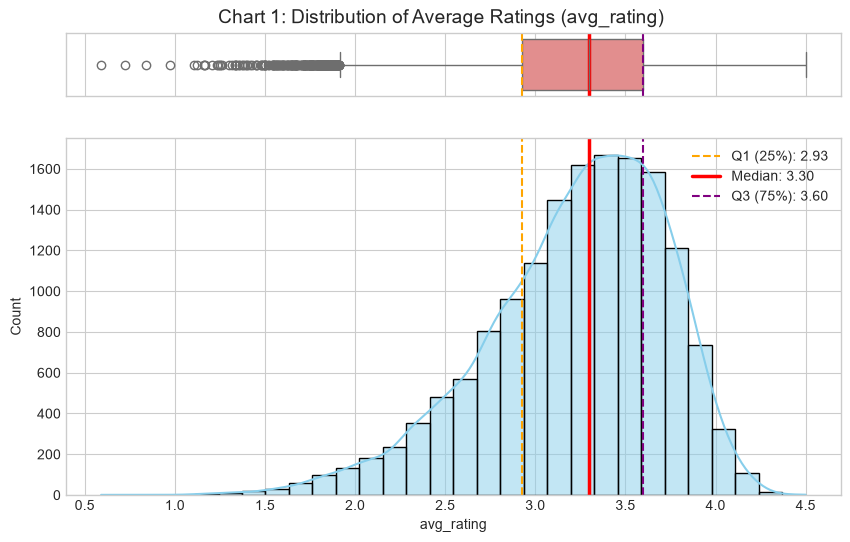

In [ ]:

q1 = df['avg_rating'].quantile(0.25)
median = df['avg_rating'].median()
q3 = df['avg_rating'].quantile(0.75)


fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, gridspec_kw={'height_ratios': (.15, .85)}, figsize=(10, 6))


sns.boxplot(x=df['avg_rating'], ax=ax_box, color='lightcoral')
ax_box.set(xlabel='')
sns.histplot(df['avg_rating'], kde=True, ax=ax_hist, bins=30, color='skyblue')


ax_hist.axvline(q1, color='orange', linestyle='--', linewidth=1.5, label=f'Q1 (25%): {q1:.2f}')
ax_hist.axvline(median, color='red', linestyle='-', linewidth=2.5, label=f'Median: {median:.2f}')
ax_hist.axvline(q3, color='purple', linestyle='--', linewidth=1.5, label=f'Q3 (75%): {q3:.2f}')


ax_box.axvline(q1, color='orange', linestyle='--', linewidth=1.5)
ax_box.axvline(median, color='red', linestyle='-', linewidth=2.5)
ax_box.axvline(q3, color='purple', linestyle='--', linewidth=1.5)


ax_hist.legend(loc='upper right') # Hiển thị bảng chú thích
plt.suptitle('Chart 1: Distribution of Average Ratings (avg_rating)', y=0.92, fontsize=14)
plt.show()

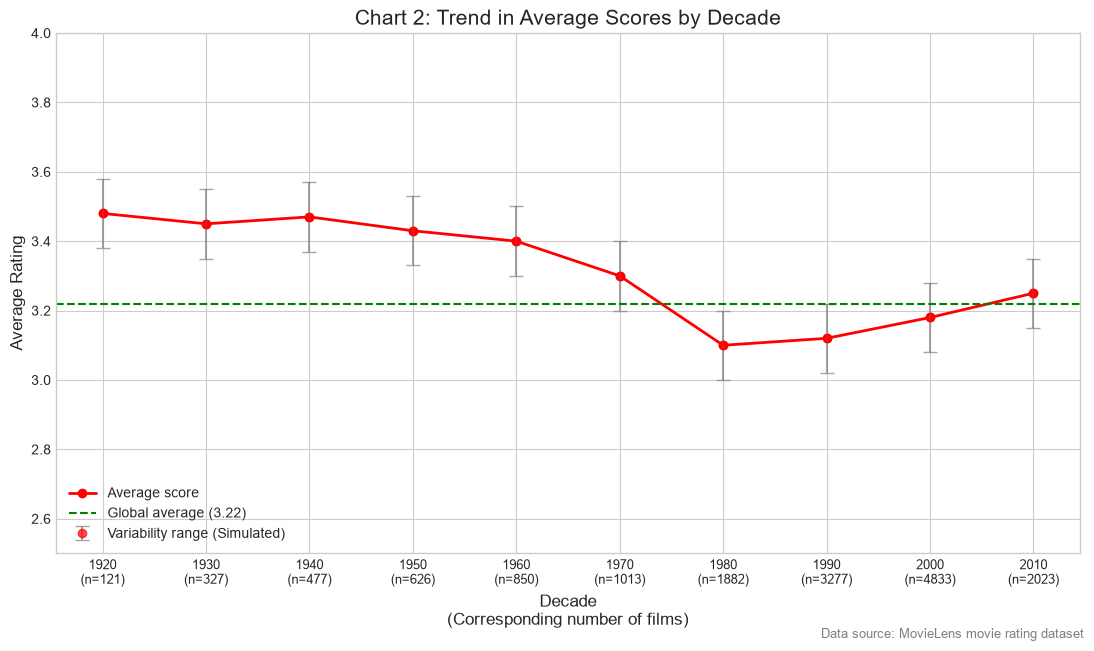

In [3]:

data = {
    'Decade': [1920, 1930, 1940, 1950, 1960, 1970, 1980, 1990, 2000, 2010],
    'avg_rating': [3.48, 3.45, 3.47, 3.43, 3.4, 3.3, 3.1, 3.12, 3.18, 3.25],
    'count': [121, 327, 477, 626, 850, 1013, 1882, 3277, 4833, 2023]
}
decade_df = pd.DataFrame(data)
decade_df['Decade'] = decade_df['Decade'].astype(str)

plt.figure(figsize=(11, 6.5))
global_mean = 3.22


plt.plot(decade_df['Decade'], decade_df['avg_rating'], marker='o', color='red', linewidth=2, label='Average score')


errors = [0.1] * len(decade_df)
plt.errorbar(decade_df['Decade'], decade_df['avg_rating'], yerr=errors, fmt='o', color='red', ecolor='gray', capsize=5, alpha=0.7, label= 'Variability range (Simulated)')


plt.axhline(global_mean, color='green', linestyle='--', linewidth=1.5, label=f'Global average ({global_mean})')


plt.title('Chart 2: Trend in Average Scores by Decade', fontsize=15)
plt.xlabel('Decade\n(Corresponding number of films)', fontsize=12)
plt.ylabel('Average Rating', fontsize=12)
plt.ylim(2.5, 4.0)


xticks_labels = [f"{row['Decade']}\n(n={row['count']})" for _, row in decade_df.iterrows()]
plt.xticks(decade_df['Decade'], xticks_labels, fontsize=9)


plt.legend(loc='lower left')
plt.figtext(0.99, 0.01, "Data source: MovieLens movie rating dataset", horizontalalignment='right', fontsize=9, color='gray')

plt.tight_layout()
plt.show()

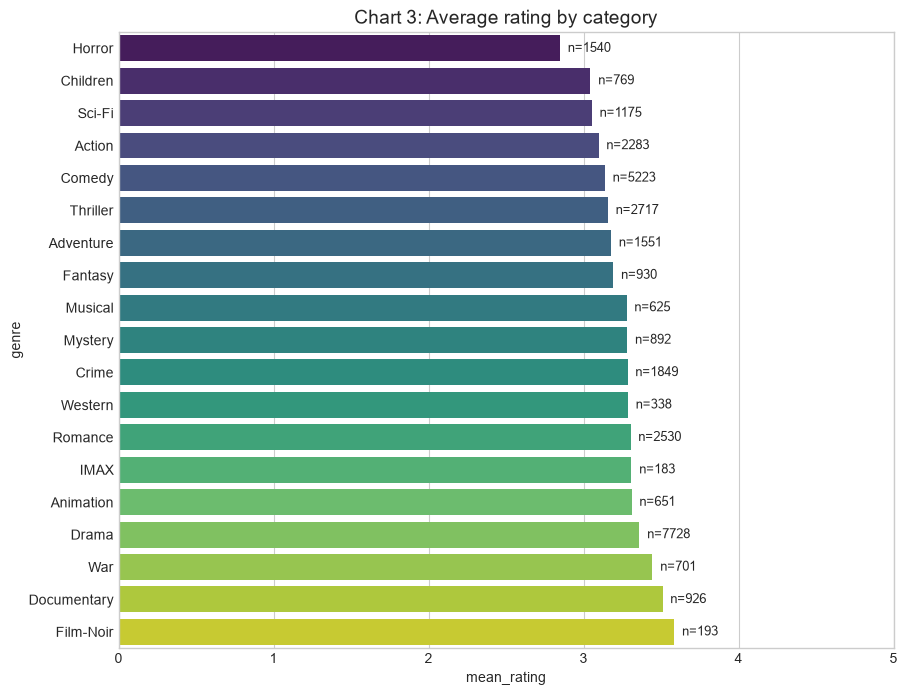

In [15]:
genre_means = [{'genre': g.replace('genre_', ''), 'mean_rating': df[df[g]==1]['avg_rating'].mean(), 'count': len(df[df[g]==1])} for g in genre_cols if len(df[df[g]==1]) > 0]
genre_df = pd.DataFrame(genre_means).sort_values('mean_rating', ascending=True).reset_index(drop=True)

genre_means = []
for g in genre_cols:
    subset = df[df[g] == 1]
    if len(subset) > 0:
        genre_name = g.replace('genre_', '')
        # Loại bỏ thể loại Unknown
        if genre_name != 'Unknown':
            genre_means.append({
                'genre': genre_name,
                'mean_rating': subset['avg_rating'].mean(),
                'count': len(subset)
            })

genre_df = pd.DataFrame(genre_means).sort_values('mean_rating', ascending=True).reset_index(drop=True)

plt.figure(figsize=(10, 8))
ax = sns.barplot(data=genre_df, x='mean_rating', y='genre', hue='genre', palette='viridis', dodge=False)

if ax.get_legend() is not None:
    ax.get_legend().remove()

for i, row in genre_df.iterrows():
    ax.text(row['mean_rating'] + 0.05, i, f"n={int(row['count'])}", va='center', fontsize=9)

plt.title('Chart 3: Average rating by category', fontsize=14)
plt.xlim(0, 5)
plt.show()

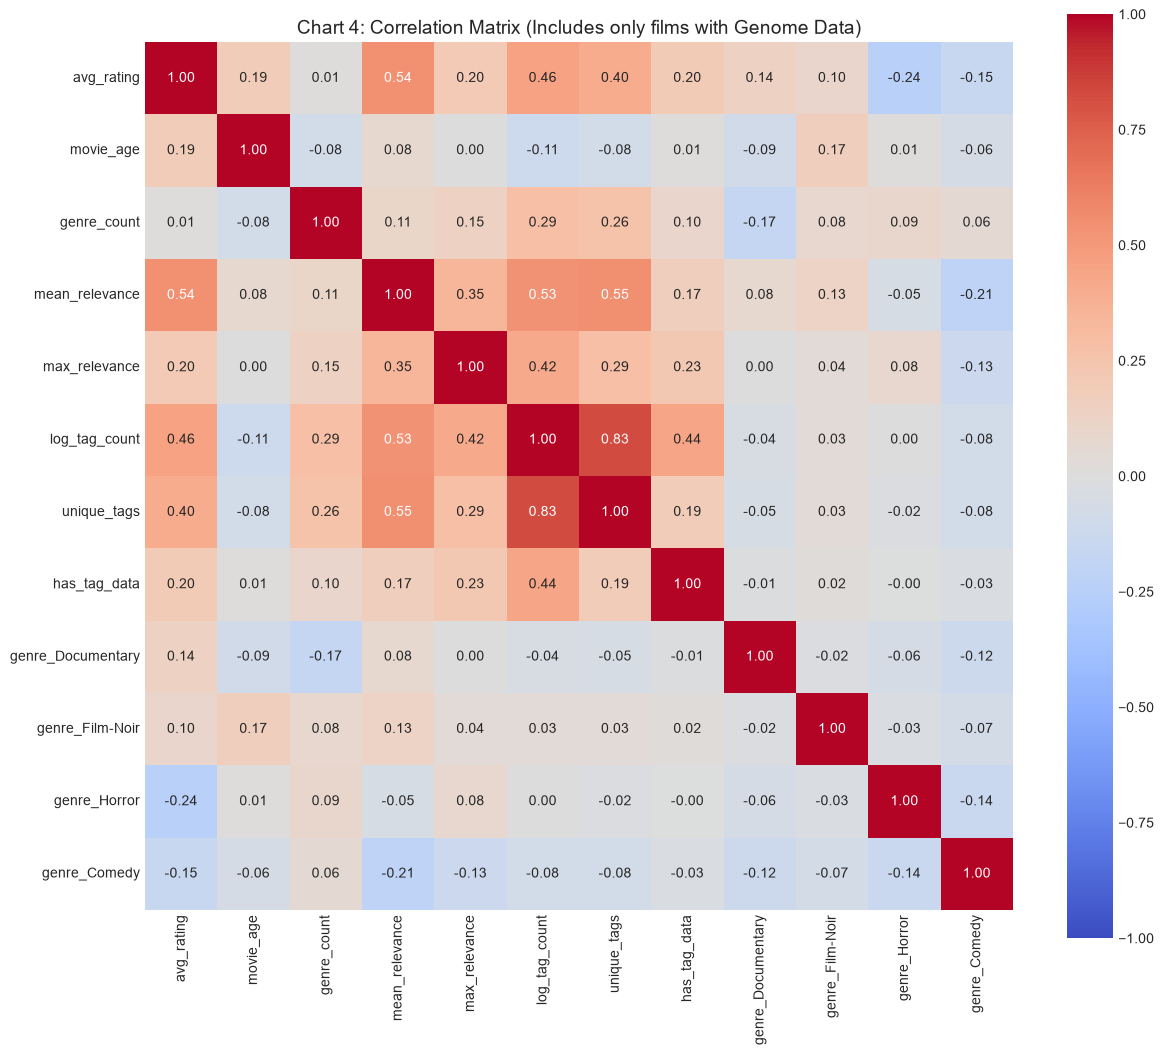

In [ ]:

df_genome = df[df['has_genome'] == 1].copy()


cols_to_plot = [
    'avg_rating', 'movie_age', 'genre_count', 'mean_relevance',
    'max_relevance', 'log_tag_count', 'unique_tags',
    'has_tag_data', 'genre_Documentary', 'genre_Film-Noir',
    'genre_Horror', 'genre_Comedy'
]


cols_exist = [c for c in cols_to_plot if c in df_genome.columns]


corr_matrix_genome = df_genome[cols_exist].corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix_genome, annot=True, fmt=".2f", cmap='coolwarm',
            vmin=-1, vmax=1, center=0, square=True,
            annot_kws={'size': 10})

plt.title('Chart 4: Correlation Matrix (Includes only films with Genome Data)', fontsize=14)
plt.show()

In [ ]:

forbidden_cols = ['rating_count', 'rating_std', 'log_rating_count', 'rating_span_days', 'genre_count']
identifier_cols = ['movieId', 'title', 'genres', 'tags_text', 'first_rated_dt', 'last_rated_dt']
target_col = ['avg_rating']

feature_cols = [col for col in df.columns if col not in (forbidden_cols + identifier_cols + target_col)]

df.to_csv(os.path.join(DATA_DIR, 'df_final.csv'), index=False)

with open(os.path.join(DATA_DIR, 'feature_cols.json'), 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, indent=4, ensure_ascii=False)

with open(os.path.join(DATA_DIR, 'target_col.json'), 'w', encoding='utf-8') as f:
    json.dump(target_col, f, indent=4)

print("Files created in:", DATA_DIR)

Files created in: C:\Users\hai27\Downloads\finalparten


In [ ]:

feature_cols = [
    "tag_count",
    "unique_tags",
    "unique_taggers",
    "genome_score_count",
    "max_relevance",
    "mean_relevance",
    "has_tag_data",
    "has_genome",
    "release_year",
    "year_missing",
    "movie_age",
    "decade",
    "log_tag_count",
    "extracted_year",
    "genre_Action",
    "genre_Adventure",
    "genre_Animation",
    "genre_Children",
    "genre_Comedy",
    "genre_Crime",
    "genre_Documentary",
    "genre_Drama",
    "genre_Fantasy",
    "genre_Film-Noir",
    "genre_Horror",
    "genre_IMAX",
    "genre_Musical",
    "genre_Mystery",
    "genre_Romance",
    "genre_Sci-Fi",
    "genre_Thriller",
    "genre_Unknown",
    "genre_War",
    "genre_Western",
    "tag_word_count",
    "relevance_range"
]

with open('feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, indent=4)

# Tạo file target_col.json
target_col = ["avg_rating"]

with open('target_col.json', 'w', encoding='utf-8') as f:
    json.dump(target_col, f, indent=4)

print("Files created.")

Files created.


In [22]:
warnings.filterwarnings('ignore')
os.makedirs('./figures', exist_ok=True)
os.makedirs('./data', exist_ok=True)
RANDOM_STATE = 42

In [23]:
df_final = pd.read_csv(r'C:\Users\hai27\Downloads\finalparten\df_final.csv')

target_col = 'avg_rating'

base_cols = ['movie_age', 'year_missing', 'has_genome', 'has_tag_data',
             'mean_relevance', 'max_relevance', 'log_tag_count']
genre_cols = [c for c in df_final.columns
              if c.startswith('genre_') and c not in ('genre_count', 'genre_Unknown')]
feature_cols = base_cols + genre_cols
print(len(genre_cols), 'genre cols |', len(feature_cols), 'features')

X = df_final[feature_cols].copy()
y = df_final[target_col].copy()

print('Số phim:', len(df_final), '| Số đặc trưng:', len(feature_cols))
print('Thiếu giá trị (tổng):', int(X.isna().sum().sum()))

19 genre cols | 26 features
Số phim: 15451 | Số đặc trưng: 26
Thiếu giá trị (tổng): 0


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (12360, 26) | Test: (3091, 26)


In [25]:
for col in ['mean_relevance', 'max_relevance']:
    if col in X_train.columns and 'has_genome' in X_train.columns:
        train_median = X_train.loc[X_train['has_genome'] == 1, col].median()
        X_train.loc[X_train['has_genome'] == 0, col] = train_median
        X_test.loc[X_test['has_genome'] == 0, col] = train_median

if 'movie_age' in X_train.columns and 'year_missing' in X_train.columns:
    train_age_med = X_train.loc[X_train['year_missing'] == 0, 'movie_age'].median()
    X_train.loc[X_train['year_missing'] == 1, 'movie_age'] = train_age_med
    X_test.loc[X_test['year_missing'] == 1, 'movie_age'] = train_age_med

print('NaN còn lại – Train:', int(X_train.isna().sum().sum()), '| Test:', int(X_test.isna().sum().sum()))

na = X_train.isna().sum()
print('Train:\n', na[na > 0])
na_t = X_test.isna().sum()
print('Test:\n', na_t[na_t > 0])

NaN còn lại – Train: 0 | Test: 0
Train:
 Series([], dtype: int64)
Test:
 Series([], dtype: int64)


In [26]:
# Điền các NaN còn sót bằng median tính CHỈ trên Train (tránh leakage)
remaining = X_train.columns[X_train.isna().any() | X_test.isna().any()].tolist()
print('Các cột còn NaN:', remaining)

for col in remaining:
    med = X_train[col].median()
    X_train[col] = X_train[col].fillna(med)
    X_test[col] = X_test[col].fillna(med)

print('NaN còn lại – Train:', int(X_train.isna().sum().sum()),
      '| Test:', int(X_test.isna().sum().sum()))

Các cột còn NaN: []
NaN còn lại – Train: 0 | Test: 0


In [27]:
models = {
    'Baseline (Mean)': DummyRegressor(strategy='mean'),
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=12,
                                           random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.08,
                            random_state=RANDOM_STATE, n_jobs=-1),
}

rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    preds[name] = y_pred
    rows.append({
        'Model': name,
        'MAE':  mean_absolute_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2':   r2_score(y_test, y_pred),
    })

df_results = pd.DataFrame(rows).set_index('Model').round(4)
df_results.to_csv('./data/df_results.csv')
df_results

,MAE,RMSE,R2
Model,,,
Baseline (Mean),0.3945,0.4997,-0.0001
Linear Regression,0.2817,0.3760,0.4337
Random Forest,0.2637,0.3615,0.4766
XGBoost,0.2572,0.3524,0.5026


In [29]:
sns.set_theme(style='whitegrid', palette='pastel', font_scale=1.0)
PASTEL = sns.color_palette('pastel')   # 0 xanh, 1 cam, 2 xanh lá, 3 đỏ, 4 tím

FIG_DIR = r'C:\Users\hai27\Downloads\finalparten\figure'
os.makedirs(FIG_DIR, exist_ok=True)

# Mỗi mô hình một màu cố định, dùng chung cho các hình
model_colors = dict(zip(df_results.index, PASTEL[:4]))

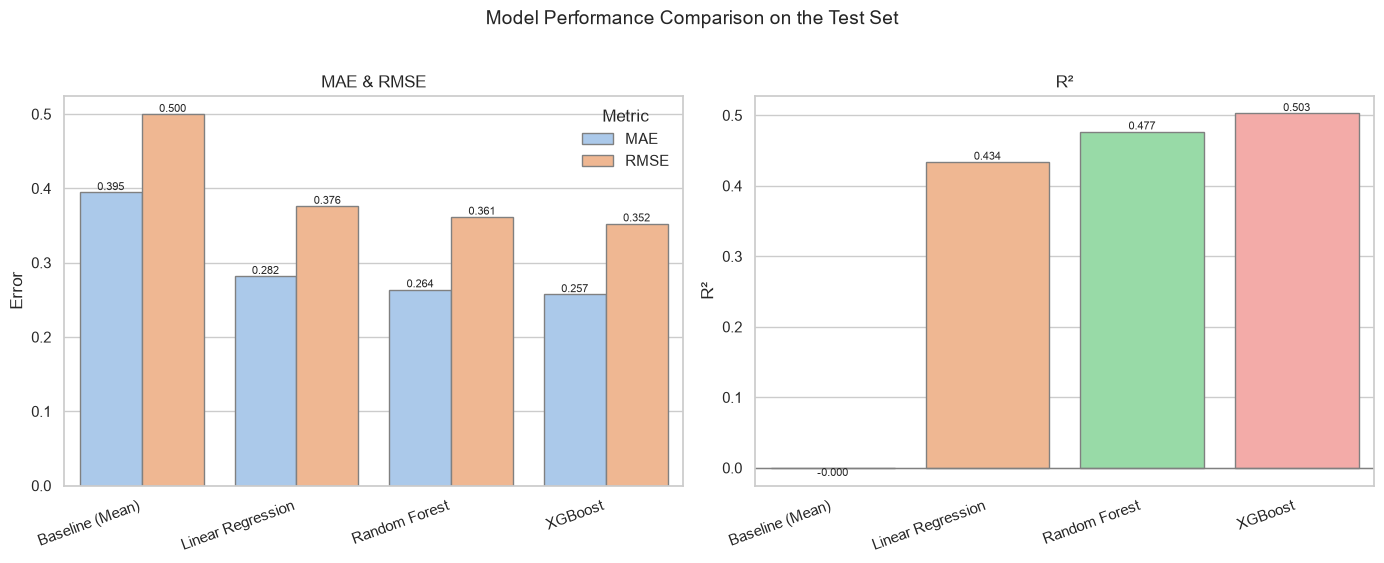

In [30]:
res = df_results.reset_index()
res_err = res.melt(id_vars='Model', value_vars=['MAE', 'RMSE'],
                   var_name='Metric', value_name='Error')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(data=res_err, x='Model', y='Error', hue='Metric',
            palette=[PASTEL[0], PASTEL[1]], edgecolor='gray', ax=axes[0])
axes[0].set_title('MAE & RMSE')
axes[0].set_xlabel('')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.3f', fontsize=8)

sns.barplot(data=res, x='Model', y='R2', hue='Model', legend=False,
            palette=model_colors, edgecolor='gray', ax=axes[1])
axes[1].set_title('R²')
axes[1].set_xlabel('')
axes[1].set_ylabel('R²')
axes[1].axhline(0, color='gray', lw=1)
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.3f', fontsize=8)

for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

fig.suptitle('Model Performance Comparison on the Test Set', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig5_model_comparison.png'), dpi=200, bbox_inches='tight')
plt.show()

Best model: XGBoost


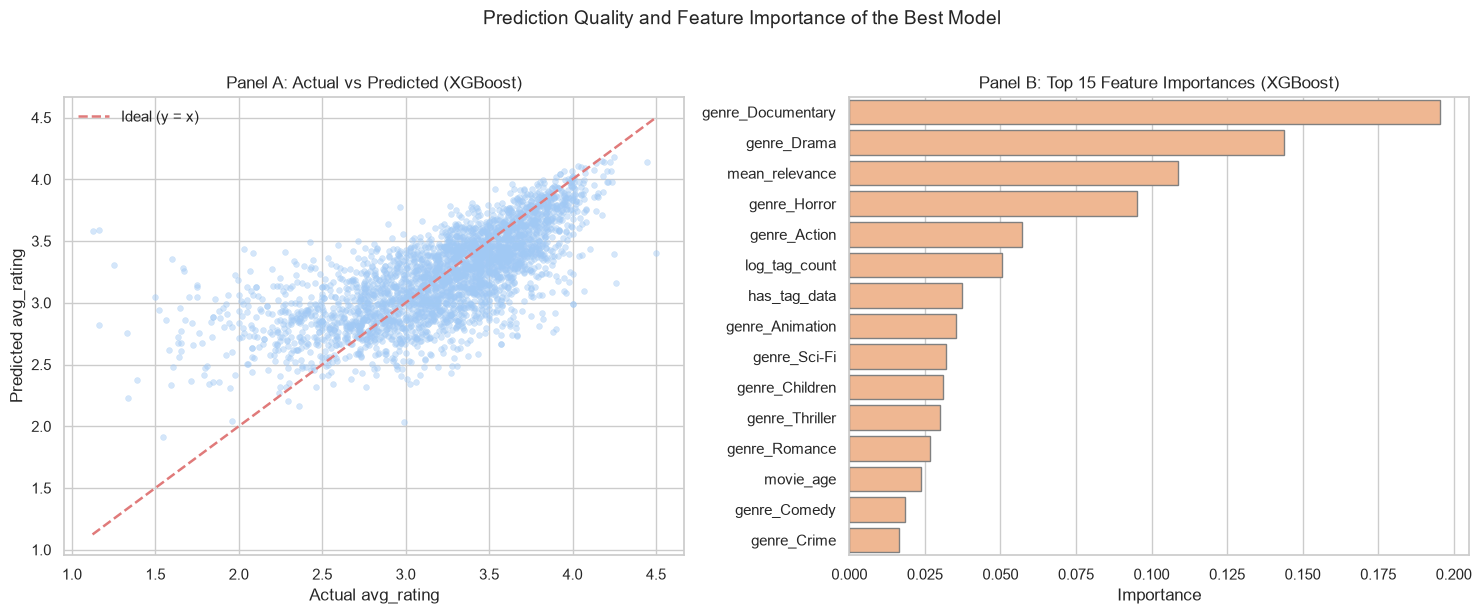

In [31]:
best_name = df_results.drop(index='Baseline (Mean)')['RMSE'].idxmin()
print('Best model:', best_name)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Panel A
yp = preds[best_name]
sns.scatterplot(x=y_test, y=yp, alpha=0.45, s=18, color=PASTEL[0],
                edgecolor=None, ax=axes[0])
lims = [min(y_test.min(), yp.min()), max(y_test.max(), yp.max())]
axes[0].plot(lims, lims, '--', color='#e07a7a', lw=1.8, label='Ideal (y = x)')
axes[0].set_xlabel('Actual avg_rating')
axes[0].set_ylabel('Predicted avg_rating')
axes[0].set_title(f'Panel A: Actual vs Predicted ({best_name})')
axes[0].legend()

# Panel B
xgb = models['XGBoost']
imp = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
sns.barplot(x=imp.values, y=imp.index, color=PASTEL[1], edgecolor='gray', ax=axes[1])
axes[1].set_title('Panel B: Top 15 Feature Importances (XGBoost)')
axes[1].set_xlabel('Importance')
axes[1].set_ylabel('')

fig.suptitle('Prediction Quality and Feature Importance of the Best Model', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig6_actual_vs_pred_importance.png'), dpi=200, bbox_inches='tight')
plt.show()

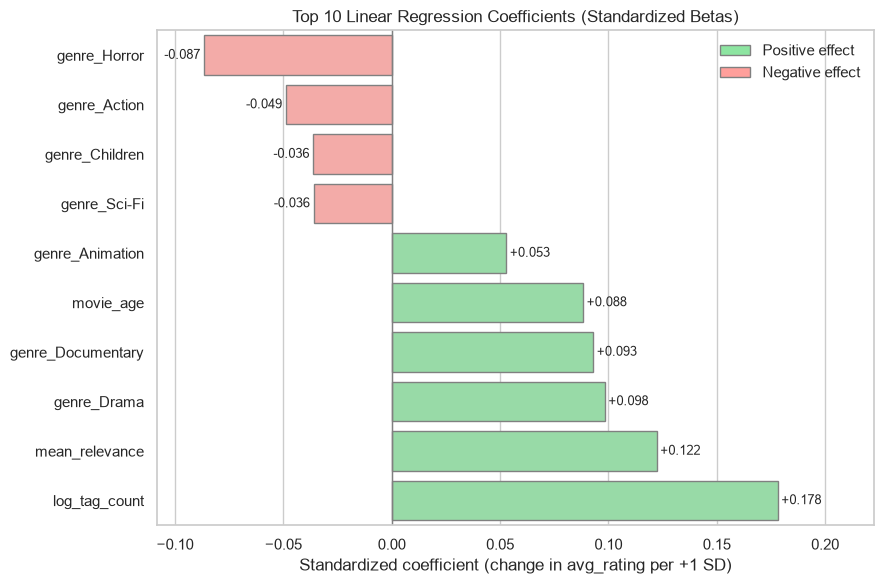

log_tag_count        0.1780
mean_relevance       0.1222
genre_Drama          0.0982
genre_Documentary    0.0929
movie_age            0.0882
genre_Animation      0.0528
genre_Romance        0.0138
genre_Mystery        0.0117
has_tag_data         0.0102
genre_War            0.0091
genre_Western        0.0082
genre_Crime          0.0064
year_missing         0.0055
genre_Film-Noir      0.0045
genre_Musical        0.0036
genre_IMAX           0.0024
genre_Fantasy       -0.0057
max_relevance       -0.0072
genre_Thriller      -0.0100
genre_Comedy        -0.0113
genre_Adventure     -0.0157
has_genome          -0.0169
genre_Sci-Fi        -0.0361
genre_Children      -0.0363
genre_Action        -0.0489
genre_Horror        -0.0866
dtype: float64


In [33]:
from sklearn.preprocessing import StandardScaler
from matplotlib.patches import Patch

# Chuẩn hóa X để các hệ số so sánh được với nhau (mean_relevance có thang 0-1,
# movie_age có thang hàng chục, các genre chỉ là 0/1).
# Chỉ dùng cho hình này; các kết quả MAE/RMSE/R² ở trên không bị ảnh hưởng.
scaler = StandardScaler().fit(X_train)
lr_std = LinearRegression().fit(scaler.transform(X_train), y_train)
coef = pd.Series(lr_std.coef_, index=X_train.columns)

# Top 10 hệ số có độ lớn (giá trị tuyệt đối) cao nhất, giữ nguyên dấu
top = coef.reindex(coef.abs().sort_values(ascending=False).head(10).index).sort_values()
colors = [PASTEL[2] if v > 0 else PASTEL[3] for v in top]

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=top.values, y=top.index, hue=top.index, legend=False,
            palette=colors, edgecolor='gray', ax=ax)
ax.axvline(0, color='gray', lw=1)

pad = 0.01 * top.abs().max()
for i, v in enumerate(top.values):
    ax.text(v + (pad if v > 0 else -pad), i, f'{v:+.3f}', va='center',
            ha='left' if v > 0 else 'right', fontsize=9)
ax.set_xlim(top.min() * 1.25, top.max() * 1.25)

ax.set_title('Top 10 Linear Regression Coefficients (Standardized Betas)')
ax.set_xlabel('Standardized coefficient (change in avg_rating per +1 SD)')
ax.set_ylabel('')
ax.legend(handles=[Patch(facecolor=PASTEL[2], edgecolor='gray', label='Positive effect'),
                   Patch(facecolor=PASTEL[3], edgecolor='gray', label='Negative effect')],
          loc='upper right')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'fig7_linear_regression_coefficients.png'), dpi=200, bbox_inches='tight')
plt.show()

print(coef.sort_values(ascending=False).round(4))

In [34]:
import os
print(os.path.abspath('./figures'))
print(os.listdir('./figures'))

import os
FIG_DIR = r'C:\Users\hai27\Downloads\finalparten\figure'
print('Thư mục có tồn tại không:', os.path.exists(FIG_DIR))
if os.path.exists(FIG_DIR):
    print('Nội dung:', os.listdir(FIG_DIR))
    os.startfile(FIG_DIR)   # tự mở thư mục này trong File Explorer

c:\Users\hai27\AppData\Local\Programs\Microsoft VS Code\figures
['fig1_missing_values_before_cleaning.png']
Thư mục có tồn tại không: True
Nội dung: ['fig5_model_comparison.png', 'fig6_actual_vs_pred_importance.png', 'fig7_linear_regression_coefficients.png']


In [35]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
best_model = models[best_name]

cv_rmse = -cross_val_score(best_model, X_train, y_train, cv=kf,
                           scoring='neg_root_mean_squared_error', n_jobs=-1)
cv_r2 = cross_val_score(best_model, X_train, y_train, cv=kf, scoring='r2', n_jobs=-1)

print(f'{best_name} – 5-Fold CV')
print(f'RMSE: {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}  (từng fold: {np.round(cv_rmse, 4)})')
print(f'R²  : {cv_r2.mean():.4f} ± {cv_r2.std():.4f}  (từng fold: {np.round(cv_r2, 4)})')

XGBoost – 5-Fold CV
RMSE: 0.3533 ± 0.0061  (từng fold: [0.3573 0.3527 0.3421 0.3546 0.3598])
R²  : 0.5065 ± 0.0077  (từng fold: [0.5044 0.5039 0.5193 0.509  0.4959])
